### Configuración
Misma celda de configuración que la Fase 3: rutas, importaciones y funciones auxiliares.

In [2]:
# ---------------------------------------------------------------------------
# Configuración, rutas e importaciones
# ---------------------------------------------------------------------------
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd

# Respaldo de visualización: el notebook funciona con o sin IPython instalado.
try:
    from IPython.display import SVG, display
    _TIENE_IPYTHON = True
except ImportError:  # pragma: no cover
    _TIENE_IPYTHON = False

    def display(*args, **kwargs):
        pass

    class SVG:  # marcador de posición para poder usar display(SVG(...))
        def __init__(self, datos):
            self.datos = datos

RAIZ = Path.cwd()
if not (RAIZ / "src").exists() and (RAIZ.parent / "src").exists():
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))

import graficos_svg as g   # librería de gráficos SVG del proyecto

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

RUTA_DATOS = RAIZ / "datos"
RUTA_REPORTES = RAIZ / "reports"
RUTA_GRAFICOS = RAIZ / "graficos"
RUTA_GRAFICOS.mkdir(exist_ok=True)
DIR_ENTREGA = RAIZ / "entrega"
DIR_ENTREGA.mkdir(exist_ok=True)


print(f"IPython disponible: {_TIENE_IPYTHON}")
print(f"pandas {pd.__version__} · numpy {np.__version__}")


def mostrar(svg: str, nombre: str | None = None) -> None:
    """Renderiza un SVG en el notebook y, si se indica, lo exporta a graficos/."""
    if nombre:
        (RUTA_GRAFICOS / f"{nombre}.svg").write_text(svg, encoding="utf-8")
    if _TIENE_IPYTHON:
        display(SVG(svg))
    else:
        print(f"[gráfico {nombre or 'sin nombre'}: {len(svg):,} caracteres SVG]")


def tabla_md(df: pd.DataFrame, dec: int = 2) -> str:
    """Convierte un DataFrame en tabla Markdown (sin depender de tabulate)."""
    enc = [str(c) for c in df.columns]
    filas = []
    for _, r in df.iterrows():
        vals = []
        for v in r:
            if isinstance(v, (int, np.integer)):
                vals.append(f"{v:,}")
            elif isinstance(v, (float, np.floating)):
                vals.append(f"{v:,.{dec}f}")
            else:
                vals.append(str(v))
        filas.append(vals)
    lineas = ["| " + " | ".join(enc) + " |",
              "|" + "|".join(["---"] * len(enc)) + "|"]
    lineas += ["| " + " | ".join(f) + " |" for f in filas]
    return "\n".join(lineas)

IPython disponible: True
pandas 3.0.6 · numpy 2.5.3


---
# Fase 5 · Desarrollo del dashboard

## 9. Visualizaciones y especificación del dashboard

El dashboard ejecutivo se entrega como archivo de Power BI construido con el
esquema en estrella de la Fase 3 . En este notebook se construyen las
**visualizaciones** que lo alimentan y se documenta la especificación de cada una:
tipo, campos, medida, interacción y buena práctica de diseño aplicada.

Se usan **más de cinco tipos de visualización distintos** (líneas, barras
agrupadas, barras horizontales, barras apiladas 100 %, Pareto, mapa de calor,
dispersión, histograma, caja y bigotes, *small multiples*, cascada, treemap,
embudo, mapa coroplético, *lollipop*, tarjetas de KPI y barras divergentes), con
segmentaciones interactivas por año, región, categoría y segmento, y un
**dashboard ejecutivo** de una sola pantalla.

Serie mensual: 48 meses · Serie anual: 4 años


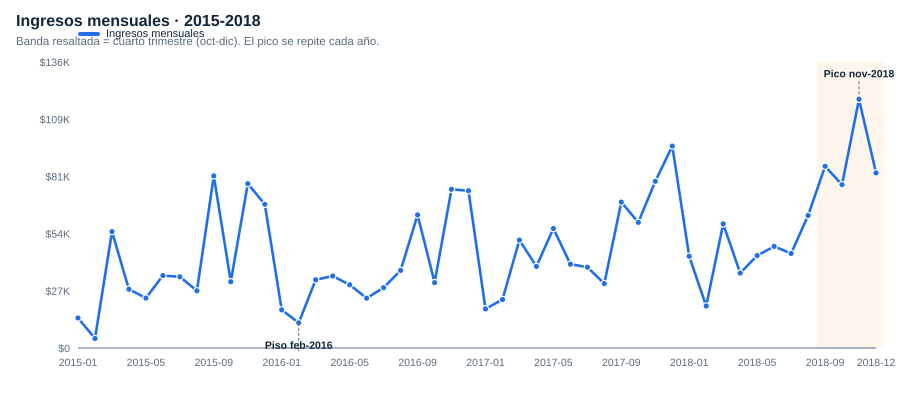


Ingresos y pedidos por año
 Anio       Ventas  Pedidos  Clientes  TicketMedio
 2015 479,856.2100      947       589     506.7100
 2016 459,436.0100     1019       567     450.8700
 2017 600,192.5500     1295       635     463.4700
 2018 722,052.0200     1661       690     434.7100

Crecimiento 2018 vs 2016: ingresos +57.2 % · pedidos +63.0 % · ticket -3.6 %


In [3]:
# ---------------------------------------------------------------------------
# 9.1 Serie temporal de ingresos y pedidos
# ---------------------------------------------------------------------------
# Carga del consolidado estadístico del pipeline para no duplicar cálculos pesados.
with open(RUTA_REPORTES / "analisis_completo.json", encoding="utf-8") as fh:
    R = json.load(fh)

mensual = pd.DataFrame(R["series"]["mensual"])
anual = pd.DataFrame(R["series"]["anual"])
print(f"Serie mensual: {len(mensual)} meses · Serie anual: {len(anual)} años")

mostrar(
    g.linea(
        mensual["AnioMes"].tolist(),
        {"Ingresos mensuales": mensual["Ventas"].tolist()},
        "Ingresos mensuales · 2015-2018",
        "Banda resaltada = cuarto trimestre (oct-dic). El pico se repite cada año.",
        banda=(44, 47),
        anotaciones=[{"x": "2018-11", "y": float(mensual.loc[mensual.AnioMes == "2018-11", "Ventas"].iat[0]),
                      "texto": "Pico nov-2018"},
                     {"x": "2016-02", "y": float(mensual.loc[mensual.AnioMes == "2016-02", "Ventas"].iat[0]),
                      "texto": "Piso feb-2016", "dy": 30}],
    ), "01_ingresos_mensuales")

print("\nIngresos y pedidos por año")
print(anual.to_string(index=False))

print(f"\nCrecimiento 2018 vs 2016: ingresos "
      f"{(anual.loc[anual.Anio == 2018, 'Ventas'].iat[0] / anual.loc[anual.Anio == 2016, 'Ventas'].iat[0] - 1)*100:+.1f} % · "
      f"pedidos {(anual.loc[anual.Anio == 2018, 'Pedidos'].iat[0] / anual.loc[anual.Anio == 2016, 'Pedidos'].iat[0] - 1)*100:+.1f} % · "
      f"ticket {(anual.loc[anual.Anio == 2018, 'TicketMedio'].iat[0] / anual.loc[anual.Anio == 2016, 'TicketMedio'].iat[0] - 1)*100:+.1f} %")

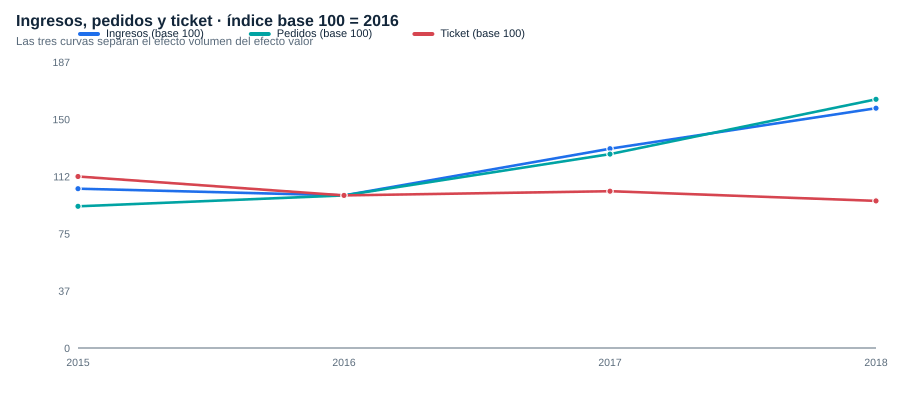

      Ingresos (base 100)  Pedidos (base 100)  Ticket (base 100)
Año                                                             
2015             104.4000             92.9000           112.4000
2016             100.0000            100.0000           100.0000
2017             130.6000            127.1000           102.8000
2018             157.2000            163.0000            96.4000


In [4]:
# ---------------------------------------------------------------------------
# 9.2 Composición anual: ingresos vs. volumen de pedidos
# ---------------------------------------------------------------------------
# Índice con base 100 en 2016 para comparar magnitudes de distinta escala.
base_2016 = anual[anual.Anio == 2016].iloc[0]
indice = pd.DataFrame({
    "Año": anual["Anio"].astype(str),
    "Ingresos (base 100)": (anual["Ventas"] / base_2016["Ventas"] * 100).round(1),
    "Pedidos (base 100)": (anual["Pedidos"] / base_2016["Pedidos"] * 100).round(1),
    "Ticket (base 100)": (anual["TicketMedio"] / base_2016["TicketMedio"] * 100).round(1),
}).set_index("Año")

mostrar(
    g.linea(
        indice.index.tolist(),
        {c: indice[c].tolist() for c in indice.columns},
        "Ingresos, pedidos y ticket · índice base 100 = 2016",
        "Las tres curvas separan el efecto volumen del efecto valor",
        colores={"Ingresos (base 100)": g.PALETA["primario"],
                 "Pedidos (base 100)": g.PALETA["secundario"],
                 "Ticket (base 100)": g.PALETA["alerta"]},
        fmt=lambda v: f"{v:,.0f}",
    ), "02_indice_base_100")
print(indice.to_string())

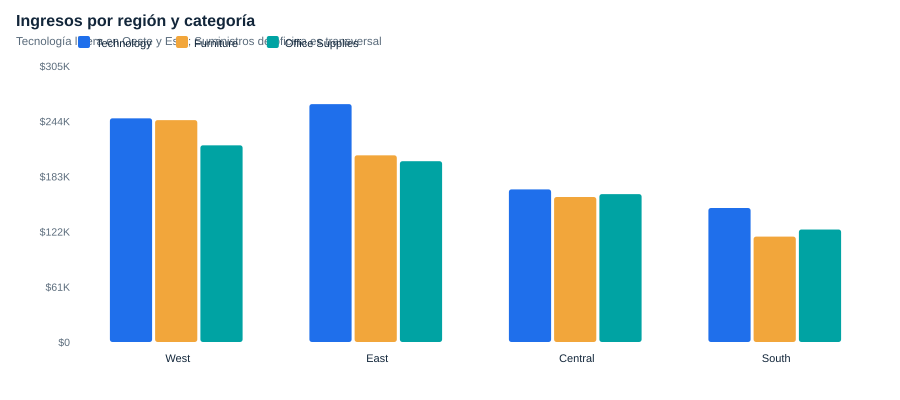

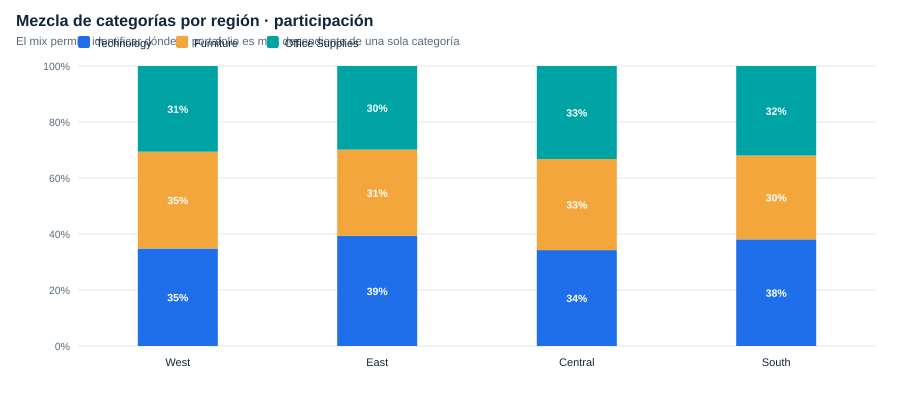

           Furniture  Office Supplies   Technology
West    245,348.0000     217,467.0000 247,405.0000
East    206,461.0000     199,941.0000 263,117.0000
Central 160,317.0000     163,590.0000 168,739.0000
South   116,531.0000     124,425.0000 148,195.0000

Participación de cada categoría dentro de la región (%):
         Furniture  Office Supplies  Technology
West       34.5000          30.6000     34.8000
East       30.8000          29.9000     39.3000
Central    32.5000          33.2000     34.3000
South      29.9000          32.0000     38.1000


In [ ]:
# ---------------------------------------------------------------------------
# 9.3 Desempeño por región y categoría
# ---------------------------------------------------------------------------
reg_cat = pd.DataFrame(R["series"]["por_region_categoria"])


if reg_cat.index.name in ["Category", "categoria"] or "Technology" in reg_cat.index:
    reg_cat = reg_cat.T

reg_cat = reg_cat.reindex(index=["West", "East", "Central", "South"])

# Normalizar nombres de columnas por si acaso (quitar espacios o buscar coincidencias parciales)
cat_esperadas = ["Technology", "Furniture", "Office Supplies"]
cols_disponibles = [c for c in cat_esperadas if c in reg_cat.columns]

mostrar(
    g.barras(
        reg_cat.index.tolist(),
        {c: reg_cat[c].tolist() for c in cols_disponibles},
        "Ingresos por región y categoría",
        "Tecnología lidera en Oeste y Este; Suministros de oficina es transversal",
        colores=g.CATEGORIA_COLOR,
    ), "03_region_categoria")

mostrar(
    g.apiladas(
        reg_cat.index.tolist(),
        {c: reg_cat[c].tolist() for c in cols_disponibles},
        "Mezcla de categorías por región · participación",
        "El mix permite identificar dónde el portafolio es más dependiente de una sola categoría",
        colores=g.CATEGORIA_COLOR,
    ), "04_mezcla_categorias")

print(reg_cat.round(0).to_string())
print("\nParticipación de cada categoría dentro de la región (%):")
print((reg_cat.div(reg_cat.sum(axis=1), axis=0) * 100).round(1).to_string())

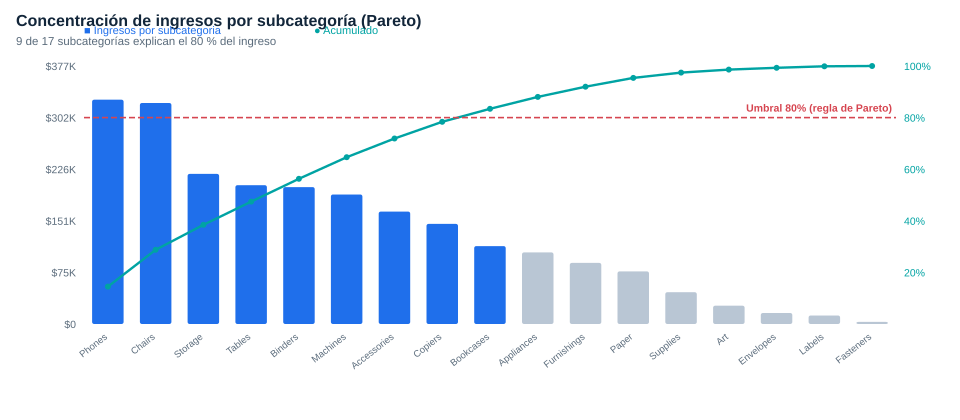

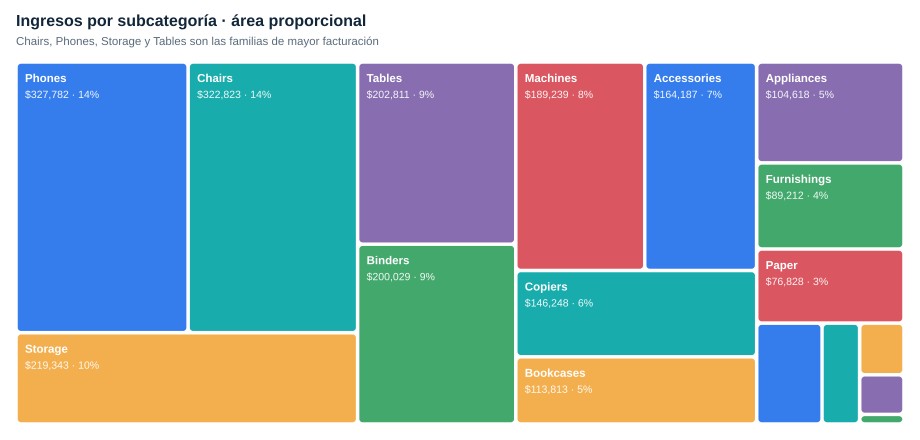

Subcategoria       Categoria       Ventas   Cuota  Acumulado
      Phones      Technology 327,782.4500 14.5000    14.5000
      Chairs       Furniture 322,822.7300 14.3000    28.8000
     Storage Office Supplies 219,343.3900  9.7000    38.5000
      Tables       Furniture 202,810.6300  9.0000    47.4000
     Binders Office Supplies 200,028.7900  8.8000    56.3000
    Machines      Technology 189,238.6300  8.4000    64.6000
 Accessories      Technology 164,186.7000  7.3000    71.9000
     Copiers      Technology 146,248.0900  6.5000    78.4000
   Bookcases       Furniture 113,813.2000  5.0000    83.4000

Top-3 cuota: 38.5 % · Top-5: 56.3 %
Gini de productos: 0.7306 · 418 de 1,849 productos (22.6 %) generan el 80 % del ingreso


In [9]:
# ---------------------------------------------------------------------------
# 9.4 Concentración del catálogo: Pareto y treemap
# ---------------------------------------------------------------------------
subcategorias = pd.DataFrame(R["series"]["subcategorias"]).sort_values("Ventas", ascending=False)
pareto_h3 = R["hipotesis"]["H3"]["pareto"]

mostrar(
    g.pareto(subcategorias["Subcategoria"].tolist(), subcategorias["Ventas"].tolist(),
             "Concentración de ingresos por subcategoría (Pareto)",
             f"{pareto_h3['subcategorias_para_80pct']} de {pareto_h3['n_subcategorias']} subcategorías "
             f"explican el 80 % del ingreso"),
    "05_pareto_subcategorias")

mostrar(
    g.treemap({r.Subcategoria: r.Ventas for r in subcategorias.itertuples()},
              "Ingresos por subcategoría · área proporcional",
              "Chairs, Phones, Storage y Tables son las familias de mayor facturación"),
    "06_treemap_subcategorias")

tabla_pareto = subcategorias.head(9).copy()
tabla_pareto["Cuota"] = (tabla_pareto["Ventas"] / subcategorias["Ventas"].sum() * 100).round(1)
tabla_pareto["Acumulado"] = (subcategorias["Ventas"].cumsum() / subcategorias["Ventas"].sum() * 100).head(9).round(1)
print(tabla_pareto.to_string(index=False))
print(f"\nTop-3 cuota: {pareto_h3['top3_cuota']*100:.1f} % · Top-5: {pareto_h3['top5_cuota']*100:.1f} %")
print(f"Gini de productos: {pareto_h3['gini_productos']:.4f} · "
      f"{pareto_h3['productos_para_80pct']:,} de {pareto_h3['n_productos']:,} productos "
      f"({pareto_h3['pct_productos_para_80pct']*100:.1f} %) generan el 80 % del ingreso")

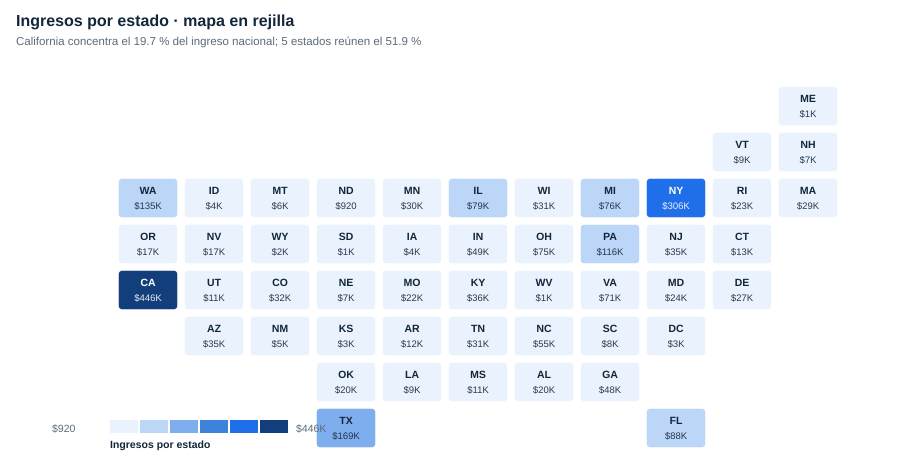

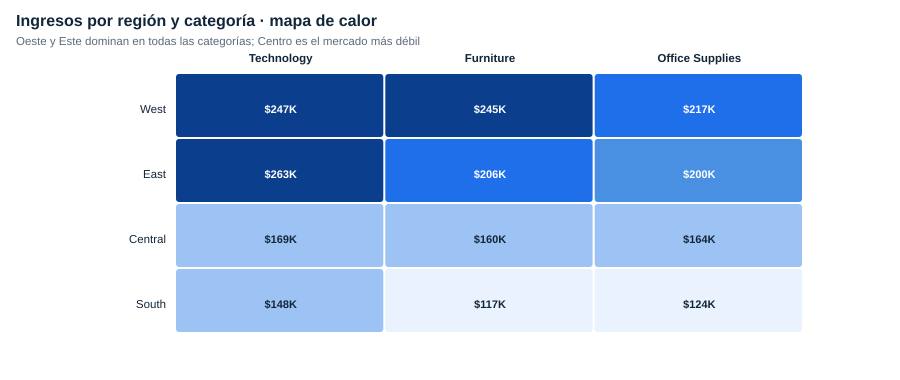

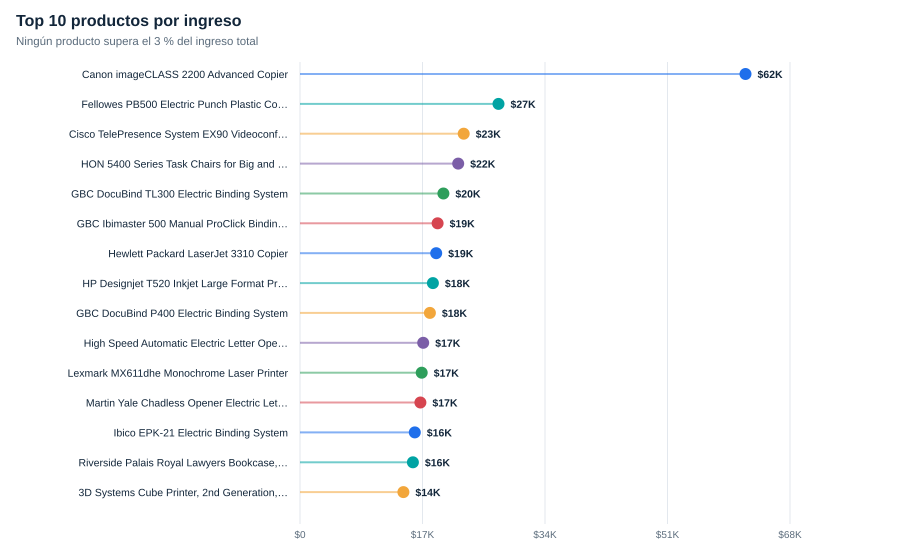

California      446,306
New York        306,361
Texas           168,573
Washington      135,207
Pennsylvania    116,277
Florida          88,437
Illinois         79,237
Michigan         76,136
Ohio             75,130
Virginia         70,637


In [10]:
# ---------------------------------------------------------------------------
# 9.5 Mapa territorial, heatmap y ranking de productos
# ---------------------------------------------------------------------------
estados = pd.Series(R["series"]["por_estado"]).sort_values(ascending=False)
codigos = {g.NOMBRE_A_ABREV[n]: v for n, v in estados.items() if n in g.NOMBRE_A_ABREV}
mostrar(
    g.mapa_estados(codigos, "Ingresos por estado · mapa en rejilla",
                   f"California concentra el {estados.iloc[0]/estados.sum()*100:.1f} % del ingreso nacional; "
                   f"5 estados reúnen el {R['kpis']['top5_estados_cuota']*100:.1f} %"),
    "07_mapa_estados")

mostrar(
    g.heatmap(
        ["West", "East", "Central", "South"],
        ["Technology", "Furniture", "Office Supplies"],
        [[reg_cat.loc[r, c] for c in ["Technology", "Furniture", "Office Supplies"]]
         for r in ["West", "East", "Central", "South"]],
        "Ingresos por región y categoría · mapa de calor",
        "Oeste y Este dominan en todas las categorías; Centro es el mercado más débil"),
    "08_heatmap_region_categoria")

top_prod = pd.DataFrame(R["series"]["top_productos"])
mostrar(
    g.lollipop(top_prod["Producto"].tolist(), top_prod["Ventas"].tolist(),
               "Top 10 productos por ingreso", "Ningún producto supera el 3 % del ingreso total"),
    "09_top_productos")

print(estados.head(10).apply(lambda v: f"{v:,.0f}").to_string())

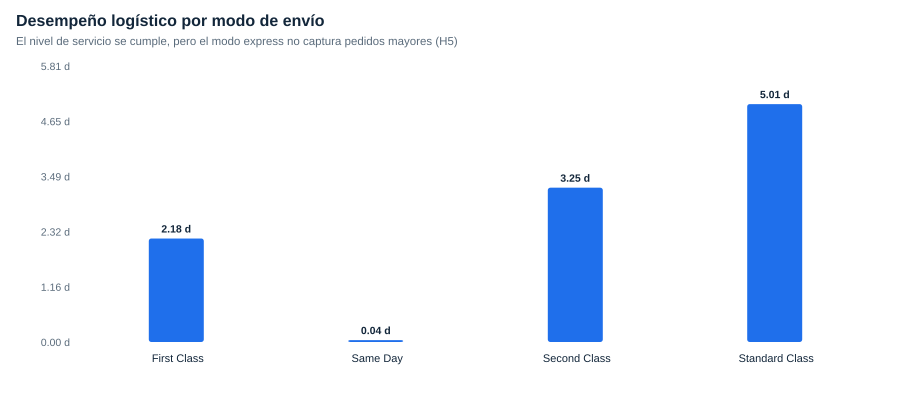

Ingresos por segmento y año
                    2015         2016         2017         2018
Consumer    262,957.0000 265,356.0000 291,143.0000 328,604.0000
Corporate   127,798.0000 119,676.0000 204,977.0000 236,044.0000
Home Office  89,102.0000  74,404.0000 104,072.0000 157,404.0000

Ticket medio por segmento:
  Consumer     ticket   452.53 USD · 2,537 pedidos · cuota  50.8 %
  Corporate    ticket   461.77 USD · 1,491 pedidos · cuota  30.4 %
  Home Office  ticket   475.37 USD ·   894 pedidos · cuota  18.8 %

 Modo de envío  Días promedio  Percentil 90  Líneas
   First Class         2.1800        3.0000    1501
      Same Day         0.0400        0.0000     538
  Second Class         3.2500        5.0000    1902
Standard Class         5.0100        7.0000    5859


In [ ]:
# ---------------------------------------------------------------------------
# 9.6 Análisis logístico y de segmentos
# ---------------------------------------------------------------------------
envio = pd.DataFrame(R["series"]["por_modo_categoria"])
envio = envio.set_index(envio.columns[0])

dias_envio = pd.DataFrame([
    {"Modo de envío": m, **v} for m, v in R["kpis"]["dias_envio_por_modo"].items()]
).set_index("Modo de envío").rename(columns={"media": "Días promedio", "p90": "Percentil 90", "lineas": "Líneas"})

mostrar(
    g.barras(
        dias_envio.index.tolist(), 
        {"Días promedio de envío": dias_envio["Días promedio"].tolist()},
        "Desempeño logístico por modo de envío",
        "El nivel de servicio se cumple, pero el modo express no captura pedidos mayores (H5)",
        fmt=lambda v: f"{v:,.2f} d"
    ), 
    "10_dias_por_modo"
)

segmento = pd.DataFrame(R["series"]["por_segmento_anio"])
print("Ingresos por segmento y año")
print(segmento.round(0).to_string())
print("\nTicket medio por segmento:")
for s, v in R["kpis"]["ticket_por_segmento"].items():
    print(f"  {s:<12} ticket {v['ticket_medio']:>8,.2f} USD · "
          f"{v['pedidos']:>5,} pedidos · cuota {v['cuota']*100:>5.1f} %")
print()
print(dias_envio.reset_index().to_string(index=False))

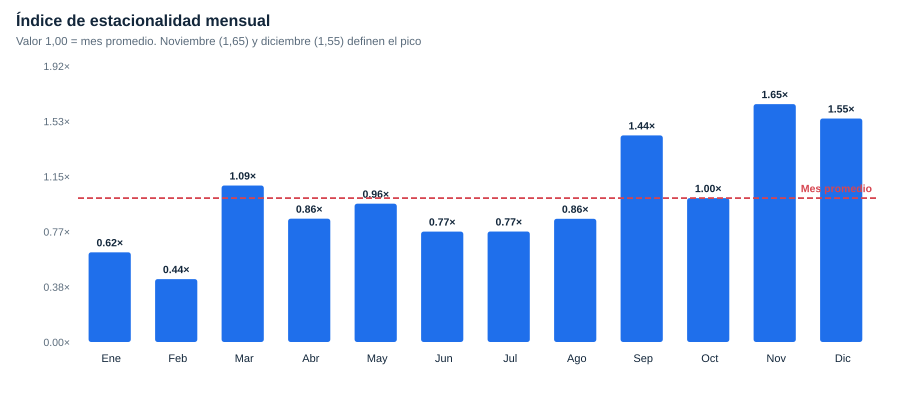

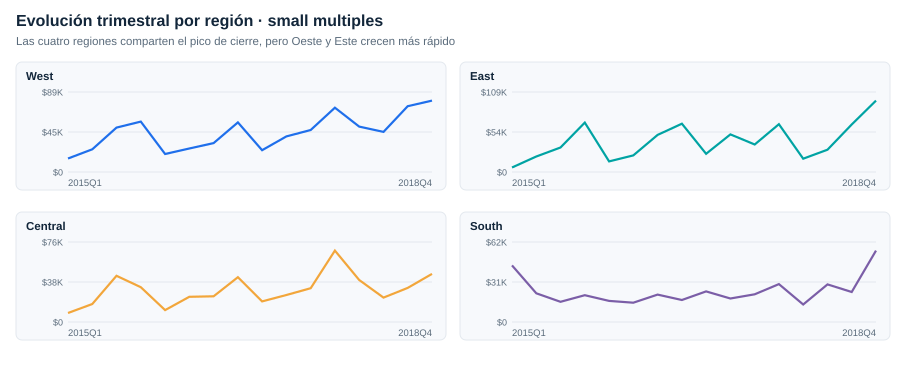

          Ene    Feb    Mar    Abr    May    Jun    Jul    Ago    Sep    Oct    Nov    Dic
Índice 0.6240 0.4370 1.0880 0.8570 0.9610 0.7670 0.7680 0.8560 1.4360 1.0000 1.6540 1.5530


In [15]:
# ---------------------------------------------------------------------------
# 9.7 Estacionalidad: índice mensual y small multiples por región
# ---------------------------------------------------------------------------
indice_est = pd.Series(R["proyeccion"]["indice_estacionalidad"])
meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

mostrar(
    g.barras(meses, {"Índice de estacionalidad": [indice_est[m] for m in meses]},
             "Índice de estacionalidad mensual",
             "Valor 1,00 = mes promedio. Noviembre (1,65) y diciembre (1,55) definen el pico",
             fmt=lambda v: f"{v:,.2f}×", linea_meta=(1.0, "Mes promedio"),
             colores={m: (g.PALETA["acento"] if indice_est[m] > 1.25 else g.PALETA["primario"]) for m in meses}),
    "11_indice_estacionalidad")

# Carga segura para reg_trim independiente de su formato original
reg_trim = pd.DataFrame(R["series"]["por_region_trimestre"])
col_regiones = reg_trim.columns[0]

# Si las regiones están en una columna, la ponemos como índice
if reg_trim[col_regiones].isin(["West", "East", "Central", "South"]).any():
    reg_trim = reg_trim.set_index(col_regiones)
elif not any(r in reg_trim.index for r in ["West", "East", "Central", "South"]):
    reg_trim = reg_trim.T
    if not any(r in reg_trim.index for r in ["West", "East", "Central", "South"]):
        reg_trim = reg_trim.set_index(reg_trim.columns[0])

# Reindexar de forma segura las regiones que existan
reg_esperadas = ["West", "East", "Central", "South"]
reg_disponibles = [r for r in reg_esperadas if r in reg_trim.index]
reg_trim = reg_trim.reindex(reg_disponibles)
trimestres = list(reg_trim.columns)

mostrar(
    g.small_multiples(
        {r: (trimestres, reg_trim.loc[r].tolist()) for r in reg_trim.index},
        "Evolución trimestral por región · small multiples",
        "Las cuatro regiones comparten el pico de cierre, pero Oeste y Este crecen más rápido",
        columnas=2, colores=g.REGION_COLOR),
    "12_small_multiples_region")

print(pd.DataFrame({"Índice": [indice_est[m] for m in meses]}, index=meses).T.round(3).to_string())

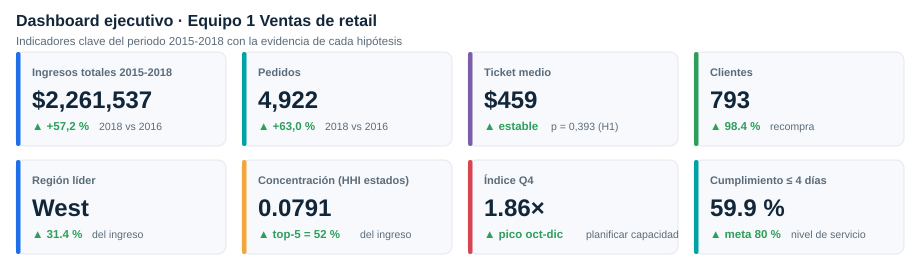

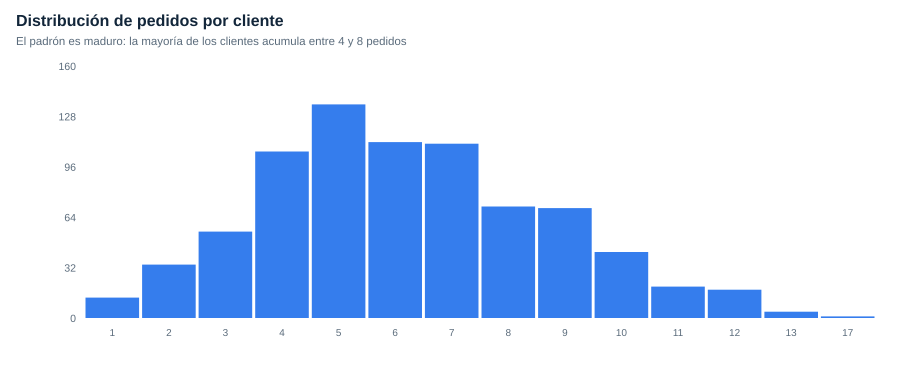

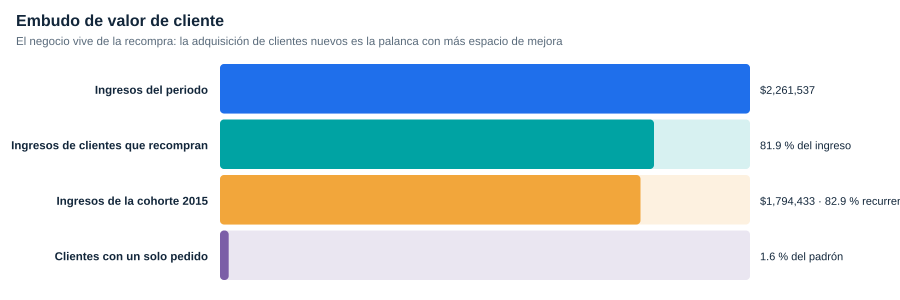

Recurrencia por cohorte (año de la primera compra):
  Cohorte 2015:  589 clientes ·  3915 pedidos ·     $1,794,433 en ventas ·  82.9 % recurrente
  Cohorte 2016:  141 clientes ·   759 pedidos ·       $344,094 en ventas ·  79.5 % recurrente
  Cohorte 2017:   52 clientes ·   229 pedidos ·       $115,498 en ventas ·  76.8 % recurrente
  Cohorte 2018:   11 clientes ·    19 pedidos ·         $7,512 en ventas ·  28.8 % recurrente


In [16]:
# ---------------------------------------------------------------------------
# 9.8 Dashboard ejecutivo (una pantalla) y embudo de retención
# ---------------------------------------------------------------------------
encabezado = R["kpis"]
tarjetas = [
    {"nombre": "Ingresos totales 2015-2018", "valor": g.dinero(encabezado["ventas_totales"]),
     "delta": "+57,2 %", "nota": "2018 vs 2016"},
    {"nombre": "Pedidos", "valor": f"{encabezado['pedidos_totales']:,}",
     "delta": "+63,0 %", "nota": "2018 vs 2016", "color": g.PALETA["secundario"]},
    {"nombre": "Ticket medio", "valor": g.dinero(encabezado["ticket_medio_global"]),
     "delta": "estable", "positivo": True, "nota": "p = 0,393 (H1)", "color": g.PALETA["violeta"]},
    {"nombre": "Clientes", "valor": f"{encabezado['clientes_totales']:,}",
     "delta": f"{encabezado['tasa_recompra']*100:.1f} %", "nota": "recompra",
     "color": g.PALETA["exito"]},
    {"nombre": "Región líder", "valor": "West",
     "delta": f"{encabezado['cuota_region']['West']*100:.1f} %", "nota": "del ingreso",
     "color": g.PALETA["primario"]},
    {"nombre": "Concentración (HHI estados)", "valor": f"{encabezado['hhi_estado']:.4f}",
     "delta": f"top-5 = {encabezado['top5_estados_cuota']*100:.0f} %", "nota": "del ingreso",
     "color": g.PALETA["acento"]},
    {"nombre": "Índice Q4", "valor": f"{encabezado['indice_estacionalidad_q4']:.2f}×",
     "delta": "pico oct-dic", "nota": "planificar capacidad",
     "color": g.PALETA["alerta"]},
    {"nombre": "Cumplimiento ≤ 4 días", "valor": f"{encabezado['cumplimiento_dias_objetivo']['objetivo_<=4_dias']*100:.1f} %",
     "delta": "meta 80 %", "nota": "nivel de servicio", "color": g.PALETA["secundario"]},
]
mostrar(g.tarjetas_kpi(tarjetas, "Dashboard ejecutivo · Equipo 1 Ventas de retail",
                       "Indicadores clave del periodo 2015-2018 con la evidencia de cada hipótesis"),
        "13_tarjetas_ejecutivas")

frecuencia = pd.DataFrame(R["series"]["frecuencia_pedidos_cliente"])
mostrar(
    g.histograma(frecuencia["clientes"].tolist(),
                 [0] + frecuencia["pedidos"].tolist(),
                 "Distribución de pedidos por cliente",
                 "El padrón es maduro: la mayoría de los clientes acumula entre 4 y 8 pedidos",
                 etiquetas=[str(p) for p in frecuencia["pedidos"]]),
    "14_frecuencia_clientes")

total = encabezado["ventas_totales"]
cohorte_2015 = encabezado["recurrencia_por_cohorte"]["2015"]
mostrar(
    g.embudo([
        ("Ingresos del periodo", 1.00, g.dinero(total)),
        ("Ingresos de clientes que recompran", encabezado["ventas_recurrentes_pct"],
         f"{encabezado['ventas_recurrentes_pct']*100:.1f} % del ingreso"),
        ("Ingresos de la cohorte 2015", cohorte_2015["ventas"] / total,
         f"{g.dinero(cohorte_2015['ventas'])} · {cohorte_2015['pct_recurrente']*100:.1f} % recurrente"),
        ("Clientes con un solo pedido", encabezado["clientes_una_compra_pct"],
         f"{encabezado['clientes_una_compra_pct']*100:.1f} % del padrón"),
    ], "Embudo de valor de cliente",
       "El negocio vive de la recompra: la adquisición de clientes nuevos es la palanca con más espacio de mejora"),
    "15_embudo_clientes")

print("Recurrencia por cohorte (año de la primera compra):")
for anio, v in encabezado["recurrencia_por_cohorte"].items():
    print(f"  Cohorte {anio}: {v['clientes']:>4} clientes · {v['pedidos']:>5} pedidos · "
          f"{g.dinero(v['ventas']):>14} en ventas · {v['pct_recurrente']*100:>5.1f} % recurrente")